# Practical Application: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

The dataset used in this study represents **17 direct marketing campaigns** carried out by a Portuguese banking institution between May 2008 and November 2010. The campaigns resulted in **79,354 customer contacts**, with the objective of promoting long-term deposit subscriptions. Customer responses from these campaigns form the basis for the classification problem analyzed in this project.

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [38]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import time
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

In [5]:
bank_df = pd.read_csv('data/bank-additional-full.csv', sep = ';')

In [6]:
bank_df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [7]:
bank_df.shape

(41188, 21)

In [8]:
bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



In [9]:
#bank_df.isnull().sum()
bank_df.isnull().sum().sum()

np.int64(0)

No missing values, but the document states that there are some values markied as 'unknown', which we are going to inspect next.

In [10]:
unknown_counts = (bank_df == 'unknown').sum()

unknown_counts[unknown_counts > 0]

job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64

In [11]:
bank_df['y'].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

In [12]:
bank_df['y'].value_counts(normalize=True) * 100

y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64

In [13]:
#bank_df['duration'].describe()
(bank_df['duration'] == 0).sum()

np.int64(4)

In [14]:
(bank_df['pdays'] == 999).mean() * 100

np.float64(96.32174419733903)

999 indicates that the client was not contacted, the data shows 96.32% of the clients havent been contacted yet.  

In [15]:
bank_df.select_dtypes(include='object').columns

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome', 'y'],
      dtype='object')

These object columns will require encoding before using KNN, Logistic Regression, SVM, or Decision Trees.

Text(0, 0.5, 'Count')

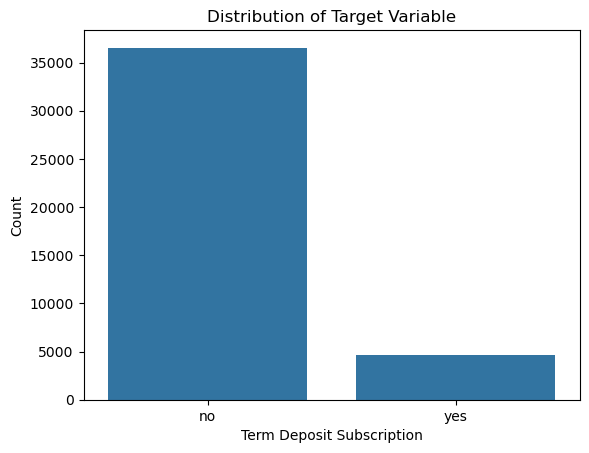

In [18]:
sns.countplot(data=bank_df, x='y')

plt.title('Distribution of Target Variable')
plt.xlabel('Term Deposit Subscription')
plt.ylabel('Count')

Text(0.5, 0, 'Subscription Rate')

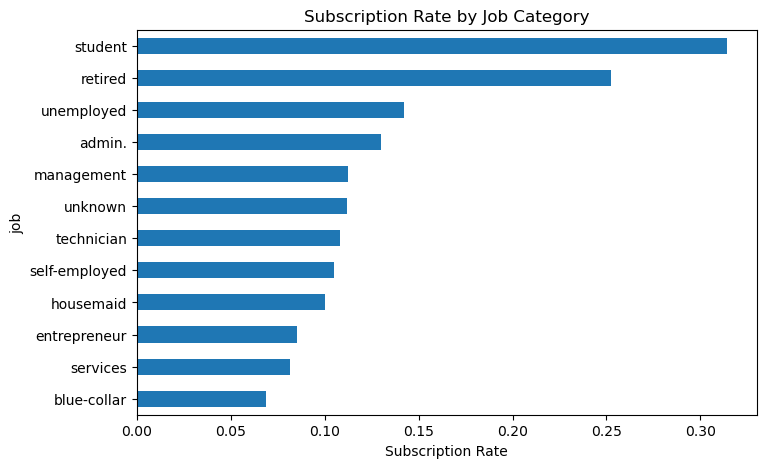

In [19]:
job_sub = pd.crosstab(
    bank_df['job'],
    bank_df['y'],
    normalize='index'
)

job_sub['yes'].sort_values().plot(
    kind='barh',
    figsize=(8,5)
)

plt.title('Subscription Rate by Job Category')
plt.xlabel('Subscription Rate')

#### Features Summary 
The dataset contains no traditional missing values (NaN). However, several categorical variables contain the value 'unknown', which represents missing information. These variables include job, marital, education, default, housing, and loan.

The numeric features are already stored as integers or floats, while categorical variables are stored as object types. No major data type conversions are required at this stage, although all categorical features will need to be encoded before training machine learning models.

Additionally, the feature pdays uses a special value of 999 to indicate that a customer was not previously contacted. The duration variable should be excluded from a realistic predictive model because its value is only known after the marketing call has completed.

### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

The business objective is to improve the effectiveness of the bank's direct marketing campaigns by identifying customers who are most likely to subscribe to a term deposit. Using customer demographic information, previous campaign interactions, and economic indicators, the bank aims to predict the target variable y, which indicates whether a client subscribes to a long term deposit (yes) or not (no). By identifying potential subscribers before making contact, the bank can allocate marketing resources more efficiently, reduce campaign costs, and improve overall campaign success rates.

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

The dataset contains four groups of variables:
1. Bank client data (age, job, marital, education, default, housing, loan)
2. Last contact information (contact, month, day_of_week, duration)
3. Campaign information (campaign, pdays, previous, poutcome)
4. Economic indicators (emp.var.rate, cons.price.idx, etc.)

Here we need to refer just the bank information, so that would mean we need to use 1st set.

In [20]:
bank_features = [
    'age',
    'job',
    'marital',
    'education',
    'default',
    'housing',
    'loan'
]

X = bank_df[bank_features]
y = bank_df['y']

print(X.head())
print("y - ")
print(y.head())

   age        job  marital    education  default housing loan
0   56  housemaid  married     basic.4y       no      no   no
1   57   services  married  high.school  unknown      no   no
2   37   services  married  high.school       no     yes   no
3   40     admin.  married     basic.6y       no      no   no
4   56   services  married  high.school       no      no  yes
y - 
0    no
1    no
2    no
3    no
4    no
Name: y, dtype: object


In [21]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        41188 non-null  int64 
 1   job        41188 non-null  object
 2   marital    41188 non-null  object
 3   education  41188 non-null  object
 4   default    41188 non-null  object
 5   housing    41188 non-null  object
 6   loan       41188 non-null  object
dtypes: int64(1), object(6)
memory usage: 2.2+ MB


<font size="4"> Encoding the target variable : 

In [22]:
y = y.map({'no': 0, 'yes': 1})####should be done once 
y.value_counts()

y
0    36548
1     4640
Name: count, dtype: int64

<font size="4"> Encoding the categorical variables : 

In [23]:
X_encoded = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

X_encoded.head()

,age,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,...,education_illiterate,education_professional.course,education_university.degree,education_unknown,default_unknown,default_yes,housing_unknown,housing_yes,loan_unknown,loan_yes
0,56,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,57,0,0,0,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0
2,37,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,40,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,56,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1


In [24]:
X_encoded.select_dtypes(include='object').columns

Index([], dtype='object')

In [25]:
print("Original shape:", X.shape)
print("Encoded shape :", X_encoded.shape)

Original shape: (41188, 7)
Encoded shape : (41188, 28)


### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [26]:

X = X_encoded

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (32950, 28)
X_test shape : (8238, 28)
y_train shape: (32950,)
y_test shape : (8238,)


In [27]:
print("Original:")
print(y.value_counts(normalize=True))

print("\nTraining:")
print(y_train.value_counts(normalize=True))

print("\nTesting:")
print(y_test.value_counts(normalize=True))

Original:
y
0    0.887346
1    0.112654
Name: proportion, dtype: float64

Training:
y
0    0.887344
1    0.112656
Name: proportion, dtype: float64

Testing:
y
0    0.887351
1    0.112649
Name: proportion, dtype: float64


In [28]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scaler.fit(X_train)

,copy,True
,with_mean,True
,with_std,True


### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [29]:
y_train.value_counts(normalize=True)

y
0    0.887344
1    0.112656
Name: proportion, dtype: float64

In [30]:

dummy = DummyClassifier(strategy='most_frequent')

dummy.fit(X_train, y_train)

baseline_score = dummy.score(X_test, y_test)

print(f"Baseline Accuracy: {baseline_score:.4f}")

Baseline Accuracy: 0.8874


<font size="3"> The baseline model predicts the majority class (y = 0, customers not subscribed to a term deposit) for all observations. Since approximately 88.7% of the customers belong to this class, the baseline accuracy is about 88.7%. Any classification model developed in this analysis should outperform this baseline to demonstrate predictive value.

### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [31]:

logreg = LogisticRegression(random_state=42)

logreg.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [32]:
y_pred = logreg.predict(X_test_scaled)
print(y_pred[:10])

[0 0 0 0 0 0 0 0 0 0]


In [33]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      1.00      0.94      7310
           1       0.00      0.00      0.00       928

    accuracy                           0.89      8238
   macro avg       0.44      0.50      0.47      8238
weighted avg       0.79      0.89      0.83      8238



C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


<font size="3"> Seems like Logistic Regression model predicted only one class (0's) and never predicted a 1. Next step will be to verify and adjust.

In [34]:
y_pred = logreg.predict(X_test_scaled)

pd.Series(y_pred).value_counts()

0    8238
Name: count, dtype: int64

In [35]:
y_test.value_counts()

y
0    7310
1     928
Name: count, dtype: int64

In [36]:
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.89      1.00      0.94      7310
           1       0.00      0.00      0.00       928

    accuracy                           0.89      8238
   macro avg       0.44      0.50      0.47      8238
weighted avg       0.79      0.89      0.83      8238



In [39]:
accuracy_score(y_test, y_pred)

0.8873512988589464

### Problem 9: Score the Model

What is the accuracy of your model?

In [40]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f}")

Model Accuracy: 0.8874


In [44]:
# Majority-class baseline
baseline_accuracy = y_train.value_counts(normalize=True).max()

print(f"Baseline Accuracy: {baseline_accuracy:.4f}")
print(f"Logistic Regression Accuracy: {accuracy:.4f}")

Baseline Accuracy: 0.8873
Logistic Regression Accuracy: 0.8874


In [45]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[7310    0]
 [ 928    0]]


<font size="3"> The Logistic Regression model predicted only the majority class (no) for all observations in the test set. As a result, the model achieved an accuracy close to the baseline accuracy of approximately 88.7%, but it failed to identify any customers who subscribed to a term deposit. This illustrates the limitations of using accuracy as the sole evaluation metric in an imbalanced classification problem and suggests that the selected customer information features alone provide limited predictive power.

### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [46]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC(random_state=42)
}


In [47]:
results = []

for name, model in models.items():

    start_time = time.time()

    model.fit(X_train_scaled, y_train)

    train_time = time.time() - start_time

    train_accuracy = model.score(X_train_scaled, y_train)

    test_accuracy = model.score(X_test_scaled, y_test)

    results.append([
        name,
        round(train_time, 4),
        round(train_accuracy, 4),
        round(test_accuracy, 4)
    ])

results


[['Logistic Regression', 0.0815, 0.8873, 0.8874],
 ['KNN', 0.0121, 0.892, 0.8795],
 ['Decision Tree', 0.1502, 0.9171, 0.8639],
 ['SVM', 69.5911, 0.8876, 0.8875]]

In [48]:
results_df = pd.DataFrame(
    results,
    columns=[
        'Model',
        'Train Time (sec)',
        'Train Accuracy',
        'Test Accuracy'
    ]
)

results_df.sort_values(
    by='Test Accuracy',
    ascending=False
)

results_df

,Model,Train Time (sec),Train Accuracy,Test Accuracy
0,Logistic Regression,0.0815,0.8873,0.8874
1,KNN,0.0121,0.8920,0.8795
2,Decision Tree,0.1502,0.9171,0.8639
3,SVM,69.5911,0.8876,0.8875


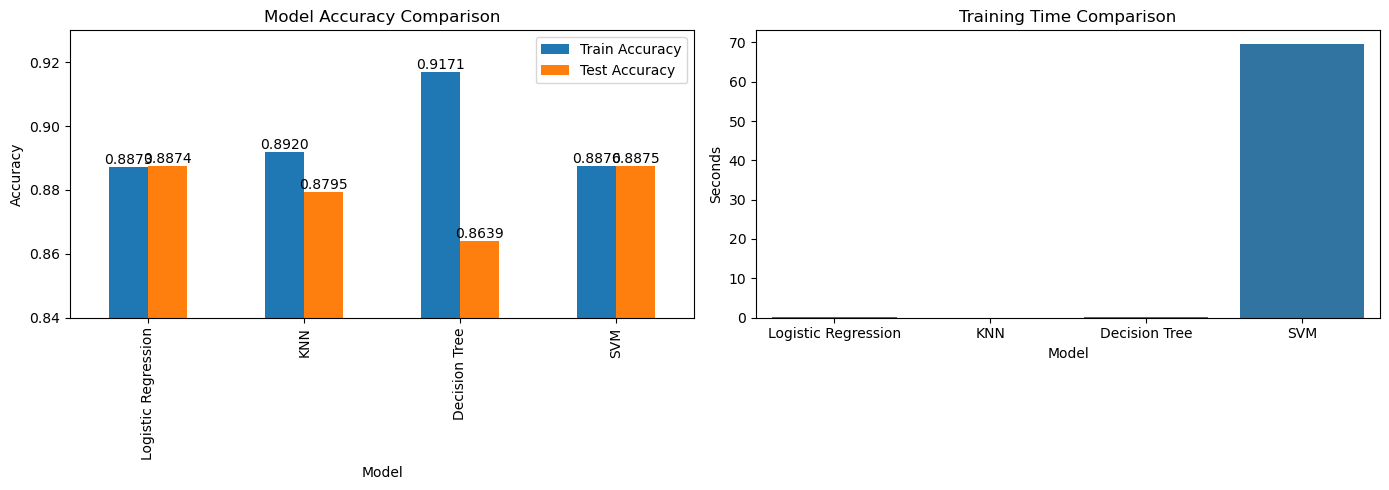

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Accuracy Comparison
results_df.plot(
    x='Model',
    y=['Train Accuracy', 'Test Accuracy'],
    kind='bar',
    ax=axes[0]
)

axes[0].set_title('Model Accuracy Comparison')
axes[0].set_ylabel('Accuracy')

# Add this line
axes[0].set_ylim(0.84, 0.93)

# Training Time Comparison
sns.barplot(
    data=results_df,
    x='Model',
    y='Train Time (sec)',
    ax=axes[1]
)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.4f')
    
axes[1].set_title('Training Time Comparison')
axes[1].set_ylabel('Seconds')

plt.tight_layout()
plt.show()


In [50]:
for name, model in models.items():
    preds = model.predict(X_test_scaled)
    print(f"\n{name}")
    print(pd.Series(preds).value_counts())


Logistic Regression
0    8238
Name: count, dtype: int64

KNN
0    8039
1     199
Name: count, dtype: int64

Decision Tree
0    7885
1     353
Name: count, dtype: int64

SVM
0    8235
1       3
Name: count, dtype: int64


<font size="3"> The four classifiers achieved similar overall accuracy scores, with Logistic Regression (88.74%) and SVM (88.75%) producing the highest test accuracy. However, further analysis revealed that Logistic Regression predicted only the majority class (no), while SVM identified only three positive cases. In contrast, KNN and Decision Tree predicted more positive subscription outcomes but achieved slightly lower test accuracy. The Decision Tree also showed evidence of overfitting, with a training accuracy of 91.71% compared to a test accuracy of 86.39%. These results suggest that accuracy alone is not sufficient for evaluating model performance in this imbalanced classification problem, and additional metrics such as precision, recall, and F1-score should be considered when assessing the models' ability to identify potential subscribers.

### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

In [51]:
lr_balanced = LogisticRegression(
    class_weight='balanced',
    random_state=42
)

lr_balanced.fit(X_train_scaled, y_train)

y_pred_balanced = lr_balanced.predict(X_test_scaled)

print(classification_report(y_test, y_pred_balanced))


              precision    recall  f1-score   support

           0       0.92      0.58      0.71      7310
           1       0.16      0.62      0.25       928

    accuracy                           0.58      8238
   macro avg       0.54      0.60      0.48      8238
weighted avg       0.84      0.58      0.66      8238



In [52]:

params = {
    'C': [0.01, 0.1, 1, 10, 100]
}

grid_lr = GridSearchCV(
    LogisticRegression(class_weight='balanced',random_state=42),
    params,
    cv=5,
    scoring='f1'
)

grid_lr.fit(X_train_scaled, y_train)

print(grid_lr.best_params_)
print(grid_lr.best_score_)

{'C': 10}
0.25558017913982967


In [53]:


params = {
    'n_neighbors': [3, 5, 7, 9, 11]
}

grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    params,
    cv=5,
    scoring='f1'
)

grid_knn.fit(X_train_scaled, y_train)

print(grid_knn.best_params_)
print(grid_knn.best_score_)

{'n_neighbors': 3}
0.13012616712348885


In [54]:

params = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10]
}

grid_tree = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    params,
    cv=5,
    scoring='f1'
)

grid_tree.fit(X_train_scaled, y_train)

print(grid_tree.best_params_)
print(grid_tree.best_score_)

{'max_depth': None, 'min_samples_split': 2}
0.1380660770219753


In [56]:
best_model = grid_lr.best_estimator_

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': best_model.coef_[0]
})

coef_df.sort_values(
    by='Coefficient',
    ascending=False
).head(10)

,Feature,Coefficient
13,marital_single,0.207800
8,job_student,0.162513
5,job_retired,0.157236
0,age,0.123161
20,education_university.degree,0.121495
12,marital_married,0.080383
21,education_unknown,0.055481
10,job_unemployed,0.049247
19,education_professional.course,0.033250
14,marital_unknown,0.028300


<font size="3.5"> **Conclusion**: Because the target variable is highly imbalanced, F1-score was used as the primary evaluation metric instead of accuracy. Logistic Regression was retrained using class_weight='balanced', which significantly improved performance on the minority class, increasing recall from 0.00 to 0.62 and improving the F1-score to 0.25. GridSearchCV was then used to tune model hyperparameters. Logistic Regression achieved the best cross-validated F1-score (0.256) with C=10, outperforming both Decision Tree (0.138) and KNN (0.130). These results indicate that Logistic Regression is the most effective classifier for this dataset and was selected as the final model.

<font size="3.5">**Limitations**: Although Logistic Regression outperformed KNN and Decision Tree models, the overall F1-score remained relatively low (0.256), indicating room for improvement. The dataset's significant class imbalance and low precision for the subscriber class suggest that the model still struggles to accurately identify positive cases without producing false positives.

<font size="3.5">**Recommendations**: Future work should investigate advanced techniques for handling class imbalance, including SMOTE and ensemble methods such as Random Forest or XGBoost. Additional feature engineering and a broader hyperparameter search may further improve the model's ability to identify potential subscribers while reducing false positive predictions.

# Copy all the libraries in one place in the end

##### Questions